<a href="https://colab.research.google.com/github/laboratoriodecodigos/Colab-Python/blob/main/Explorando_DeepFace.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip -q install deepface

In [2]:
!git clone https://github.com/serengil/deepface.git repo

Cloning into 'repo'...
remote: Enumerating objects: 10312, done.
remote: Counting objects: 100% (108/108), done.
remote: Compressing objects: 100% (84/84), done.
remote: Total 10312 (delta 34), reused 54 (delta 21), pack-reused 10204 (from 2)
Receiving objects: 100% (10312/10312), 57.55 MiB | 32.47 MiB/s, done.
Resolving deltas: 100% (6735/6735), done.


26-10-30 17:06:08 - Directory /root/.deepface has been created
26-10-30 17:06:08 - Directory /root/.deepface/weights has been created
62 imágenes disponibles


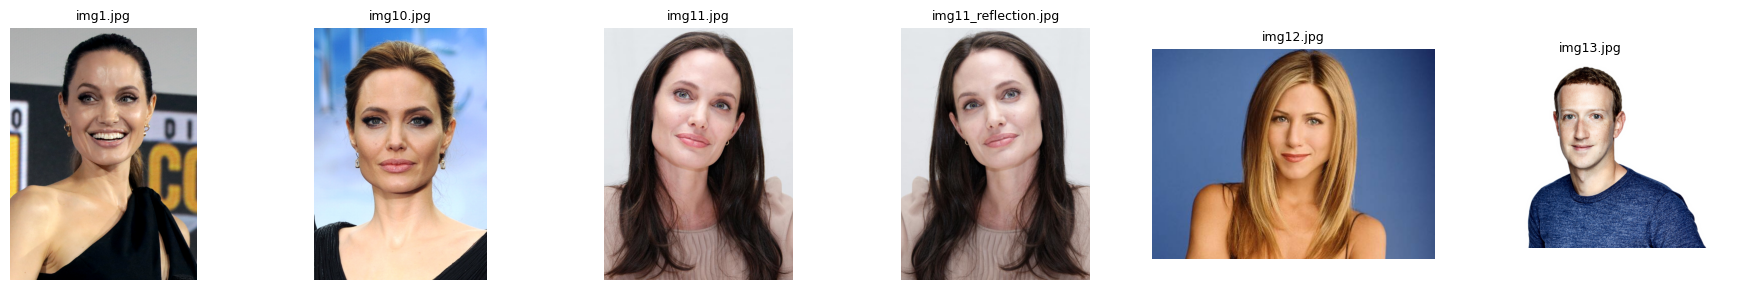

In [3]:
import os, glob, time, cv2, numpy as np, pandas as pd
import matplotlib.pyplot as plt
from deepface import DeepFace

DATASET = "repo/tests/unit/dataset"
imgs = sorted(glob.glob(f"{DATASET}/img*.jpg"))
print(len(imgs), "imágenes disponibles")

def load(p): return cv2.cvtColor(cv2.imread(p), cv2.COLOR_BGR2RGB)

def show(paths, titles=None, size=3):
    paths = [paths] if isinstance(paths, str) else paths
    fig, ax = plt.subplots(1, len(paths), figsize=(size*len(paths), size))
    ax = np.atleast_1d(ax)
    for i, p in enumerate(paths):
        ax[i].imshow(load(p) if isinstance(p, str) else p); ax[i].axis("off")
        if titles: ax[i].set_title(titles[i], fontsize=9)
    plt.tight_layout(); plt.show()

show(imgs[:6], [os.path.basename(p) for p in imgs[:6]])

## 1. `verify` → ¿Son la misma persona?

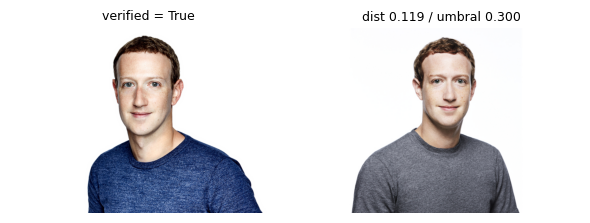

{'verified': True, 'distance': 0.118537, 'threshold': 0.3, 'model': 'Facenet512', 'similarity_metric': 'cosine', 'time': 17.43}


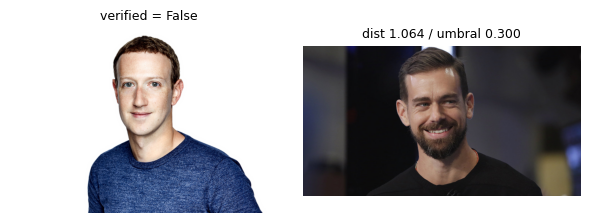

{'verified': False, 'distance': 1.063795, 'threshold': 0.3, 'model': 'Facenet512', 'similarity_metric': 'cosine', 'time': 18.59}


In [28]:
img1, img2, img3 = f"{DATASET}/img13.jpg", f"{DATASET}/img14.jpg", f"{DATASET}/img17.jpg"
for a, b in [(img1, img2), (img1, img3)]:
    r = DeepFace.verify(img1_path=a, img2_path=b,
                        model_name="Facenet512", detector_backend="retinaface")
    show([a, b], [f"verified = {r['verified']}",
                  f"dist {r['distance']:.3f} / umbral {r['threshold']:.3f}"])
    print({k: r[k] for k in ["verified", "distance",
                             "threshold", "model", "similarity_metric", "time"]})

### Comparar métricas de distancia

In [5]:
rows = []
for m in ["cosine", "euclidean", "euclidean_l2"]:
    r = DeepFace.verify(img1, img2, model_name="ArcFace", distance_metric=m)
    rows.append([m, r["verified"],
                 round(r["distance"], 4), round(r["threshold"], 4)])
pd.DataFrame(rows, columns=["métrica", "verified", "distancia", "umbral"])

26-10-30 17:09:16 - 🔗 arcface_weights.h5 will be downloaded from https://github.com/serengil/deepface_models/releases/download/v1.0/arcface_weights.h5 to /root/.deepface/weights/arcface_weights.h5...


Downloading...
From: https://github.com/serengil/deepface_models/releases/download/v1.0/arcface_weights.h5
To: /root/.deepface/weights/arcface_weights.h5
100%|██████████| 137M/137M [00:00<00:00, 218MB/s]


,métrica,verified,distancia,umbral
0,cosine,True,0.5069,0.68
1,euclidean,True,3.8720,4.15
2,euclidean_l2,True,1.0069,1.13


## 2. `analyze` → edad, género, emoción y etnia

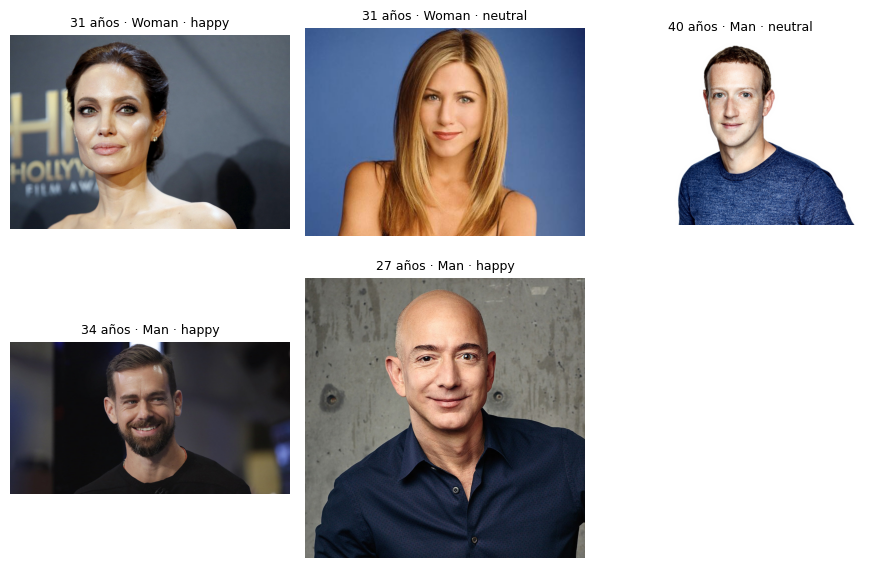

,imagen,edad,género,emoción,etnia
0,img4.jpg,31,Woman,happy,white
1,img12.jpg,31,Woman,neutral,white
2,img13.jpg,40,Man,neutral,white
3,img17.jpg,34,Man,happy,white
4,img20.jpg,27,Man,happy,middle eastern


In [29]:
paths = [f"{DATASET}/img{i}.jpg" for i in (4, 12, 13, 17, 20)]
paths = [p for p in paths if os.path.exists(p)] or imgs[3:7]
out = []
for p in paths:
    r = DeepFace.analyze(p, actions=["age",
                                     "gender", "emotion", "race"],
                         enforce_detection=False, silent=True)[0]
    out.append([os.path.basename(p), r["age"],
                r["dominant_gender"], r["dominant_emotion"], r["dominant_race"]])

# Modificamos la visualización para mostrar un máximo de 3 imágenes por fila
def show_grid(paths, titles=None, cols=3, size=3):
    n = len(paths)
    rows = (n + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(size * cols, size * rows))
    axes = np.atleast_1d(axes).flatten()
    for i in range(len(axes)):
        if i < n:
            p = paths[i]
            axes[i].imshow(load(p) if isinstance(p, str) else p)
            axes[i].axis("off")
            if titles:
                axes[i].set_title(titles[i], fontsize=9)
        else:
            axes[i].axis("off")
    plt.tight_layout()
    plt.show()

show_grid(paths, [f"{o[1]} años · {o[2]} · {o[3]}" for o in out], cols=3)
pd.DataFrame(out, columns=["imagen", "edad", "género", "emoción", "etnia"])

### Probabilidades de emociones

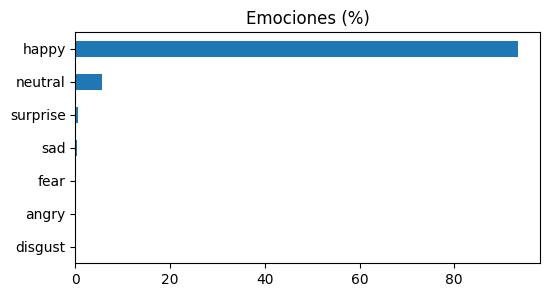

In [7]:
r = DeepFace.analyze(paths[0], actions=["emotion"],
                     enforce_detection=False, silent=True)[0]
pd.Series(r["emotion"]).sort_values().plot.barh(figsize=(6, 3),
                                                title="Emociones (%)"); plt.show()

## 3. `extract_faces` y comparación de detectores

In [13]:
!pip install ultralytics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 10.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [ultralytics]


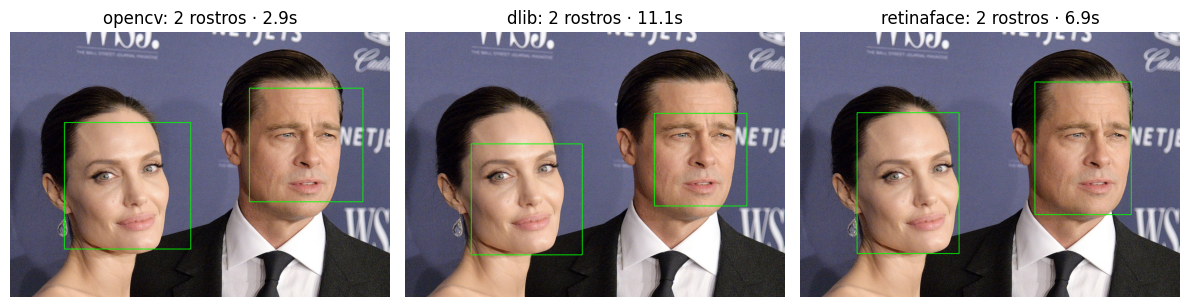

In [16]:
src = f"{DATASET}/couple.jpg" if os.path.exists(f"{DATASET}/couple.jpg") else imgs[0]
backends = ["opencv", "dlib", "retinaface"]
fig, ax = plt.subplots(1, len(backends),
                       figsize=(4*len(backends), 4))
ax = np.atleast_1d(ax)
for a, b in zip(ax, backends):
    try:
        t = time.time()
        faces = DeepFace.extract_faces(src, detector_backend=b,
                                       align=True, enforce_detection=False)
        im = load(src).copy()
        for f in faces:
            fa = f["facial_area"]
            cv2.rectangle(im, (fa["x"],
                               fa["y"]),
                                (fa["x"]+fa["w"],
                                 fa["y"]+fa["h"]), (0, 255, 0), 3)
        a.imshow(im);
        a.set_title(f"{b}: {len(faces)} rostros · {time.time()-t:.1f}s")
    except Exception as e:
        print(f"Error detallado en {b}: {str(e)}")
        a.set_title(f"{b}: error")
    a.axis("off")
plt.tight_layout(); plt.show()

### Rostros recortados y alineados

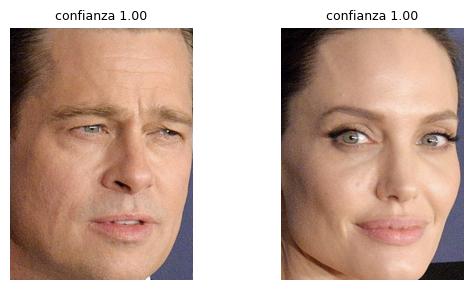

In [17]:
faces = DeepFace.extract_faces(src,
                               detector_backend="retinaface", align=True)
show([(f["face"] * 255).astype("uint8") for f in faces],
     [f"confianza {f['confidence']:.2f}" for f in faces])

## 4. `represent` → embeddings

=== HUELLA DIGITAL FACIAL (EMBEDDING) ===
El rostro ha sido transformado en un vector único de 512 características numéricas.
• Valor Máximo (Rasgo más fuerte): 3.1093
• Valor Mínimo (Rasgo más débil): -3.1443
• Promedio general de la señal: 0.0537



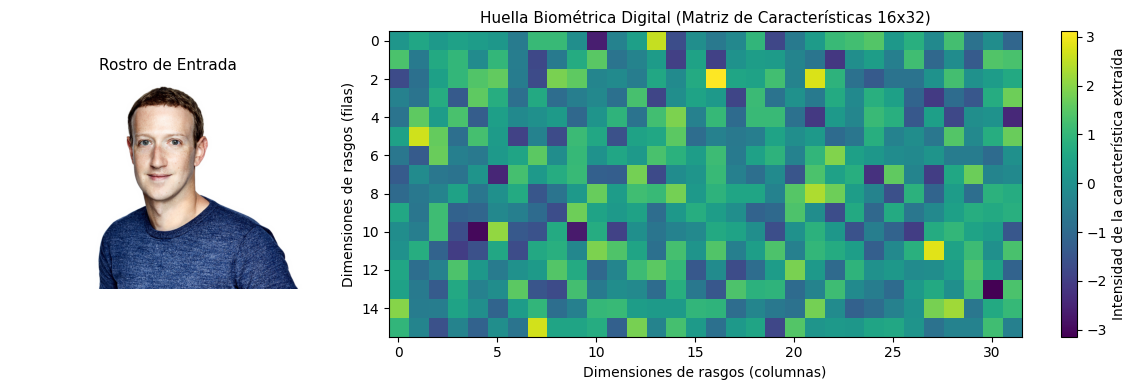

In [30]:
emb = DeepFace.represent(img1, model_name="Facenet512",
                         detector_backend="retinaface")[0]["embedding"]
emb_np = np.array(emb)

# Explicación intuitiva para el usuario final
print("=== HUELLA DIGITAL FACIAL (EMBEDDING) ===")
print(f"El rostro ha sido transformado en un vector único de\
 {len(emb_np)} características numéricas.")
print(f"• Valor Máximo (Rasgo más fuerte): {emb_np.max():.4f}")
print(f"• Valor Mínimo (Rasgo más débil): {emb_np.min():.4f}")
print(f"• Promedio general de la señal: {emb_np.mean():.4f}\n")

# Redimensionamos el vector de 512 a una grilla de 16x32
#para representarlo como un mapa de calor o código de barras facial
grid_emb = emb_np.reshape((16, 32))

fig, axes = plt.subplots(1, 2, figsize=(12, 4),
                         gridspec_kw={'width_ratios': [1, 2.5]})

# Lado izquierdo: El rostro analizado
axes[0].imshow(load(img1))
axes[0].set_title("Rostro de Entrada", fontsize=11)
axes[0].axis("off")

# Lado derecho: Representación visual del embedding como mapa de calor
im_map = axes[1].imshow(grid_emb, cmap="viridis", aspect="auto")
axes[1].set_title("Huella Biométrica Digital (Matriz de Características 16x32)",
                  fontsize=11)
axes[1].set_xlabel("Dimensiones de rasgos (columnas)")
axes[1].set_ylabel("Dimensiones de rasgos (filas)")
fig.colorbar(im_map, ax=axes[1], label="Intensidad de la característica extraída")

plt.tight_layout()
plt.show()

## 5. Comparar modelos de reconocimiento

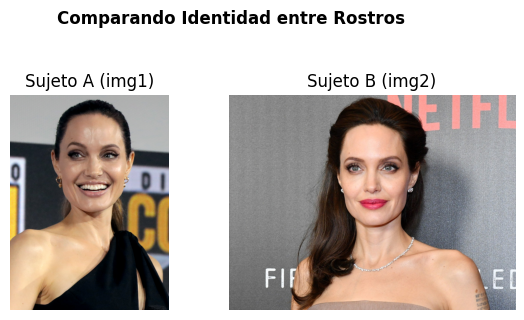

,Modelo Evaluado,¿Misma Persona?,Distancia Calculada,Umbral Límite,Tiempo (segundos)
0,VGG-Face,✅ Sí,0.416,0.680,5.01
1,Facenet,✅ Sí,0.235,0.400,5.91
2,Facenet512,✅ Sí,0.258,0.300,4.43
3,ArcFace,✅ Sí,0.507,0.680,5.44
4,SFace,✅ Sí,0.368,0.593,4.77


In [21]:
models = ["VGG-Face", "Facenet", "Facenet512", "ArcFace", "SFace"]
rows = []

# Mostramos primero de forma gráfica las caras comparadas para dar contexto visual inmediato
fig, axes = plt.subplots(1, 2, figsize=(6, 3))
axes[0].imshow(load(img1))
axes[0].set_title("Sujeto A (img1)")
axes[0].axis("off")

axes[1].imshow(load(img2))
axes[1].set_title("Sujeto B (img2)")
axes[1].axis("off")
plt.suptitle("Comparando Identidad entre Rostros",
             fontsize=12, fontweight='bold', y=1.05)
plt.tight_layout()
plt.show()

for m in models:
    try:
        t = time.time()
        r = DeepFace.verify(img1, img2, model_name=m)
        rows.append([m, "✅ Sí" if r["verified"] else "❌ No",
                     round(r["distance"], 3), round(r["threshold"], 3),
                     round(time.time()-t, 2)])
    except Exception as e:
        rows.append([m, "Error", None, None, None])

# Presentamos los resultados en una tabla elegante de Pandas
pd.DataFrame(rows, columns=["Modelo Evaluado", "¿Misma Persona?",
                            "Distancia Calculada", "Umbral Límite", "Tiempo (segundos)"])

## 6. `find` → buscar en una base de rostros

,identity,distance,threshold
0,db/img13.jpg,0.000000,0.3
1,db/img14.jpg,0.118537,0.3
2,db/img15.jpg,0.247206,0.3


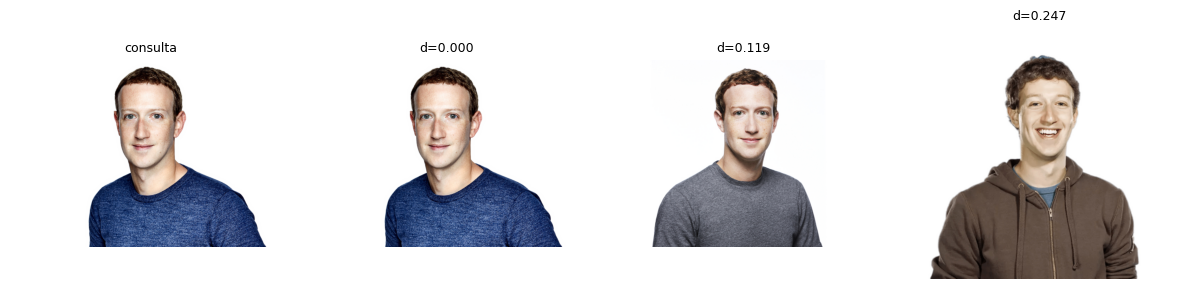

In [31]:
os.makedirs("db", exist_ok=True)
for p in imgs[:25]: os.system(f"cp {p} db/")
query = f"{DATASET}/img13.jpg"
dfs = DeepFace.find(img_path=query, db_path="db", model_name="Facenet512",
                    detector_backend="retinaface",
                    enforce_detection=False, silent=True)
res = dfs[0].head(4)
display(res[["identity", "distance", "threshold"]])
show([query] + list(res["identity"]), ["consulta"] +
     [f"d={d:.3f}" for d in res["distance"]])

## 7. Anti-spoofing (detectar fotos/pantallas falsas)

=== ANALIZANDO INTEGRIDAD FACIAL (ANTI-SPOOFING) ===



Downloading...
From: https://github.com/serengil/deepface_models/releases/download/v1.0/2.7_80x80_MiniFASNetV2.h5
To: /root/.deepface/weights/2.7_80x80_MiniFASNetV2.h5


26-10-30 17:40:20 - 🔗 2.7_80x80_MiniFASNetV2.h5 will be downloaded from https://github.com/serengil/deepface_models/releases/download/v1.0/2.7_80x80_MiniFASNetV2.h5 to /root/.deepface/weights/2.7_80x80_MiniFASNetV2.h5...


100%|██████████| 2.23M/2.23M [00:00<00:00, 186MB/s]


26-10-30 17:40:21 - 🔗 4_0_0_80x80_MiniFASNetV1SE.h5 will be downloaded from https://github.com/serengil/deepface_models/releases/download/v1.0/4_0_0_80x80_MiniFASNetV1SE.h5 to /root/.deepface/weights/4_0_0_80x80_MiniFASNetV1SE.h5...


Downloading...
From: https://github.com/serengil/deepface_models/releases/download/v1.0/4_0_0_80x80_MiniFASNetV1SE.h5
To: /root/.deepface/weights/4_0_0_80x80_MiniFASNetV1SE.h5
100%|██████████| 2.29M/2.29M [00:00<00:00, 170MB/s]


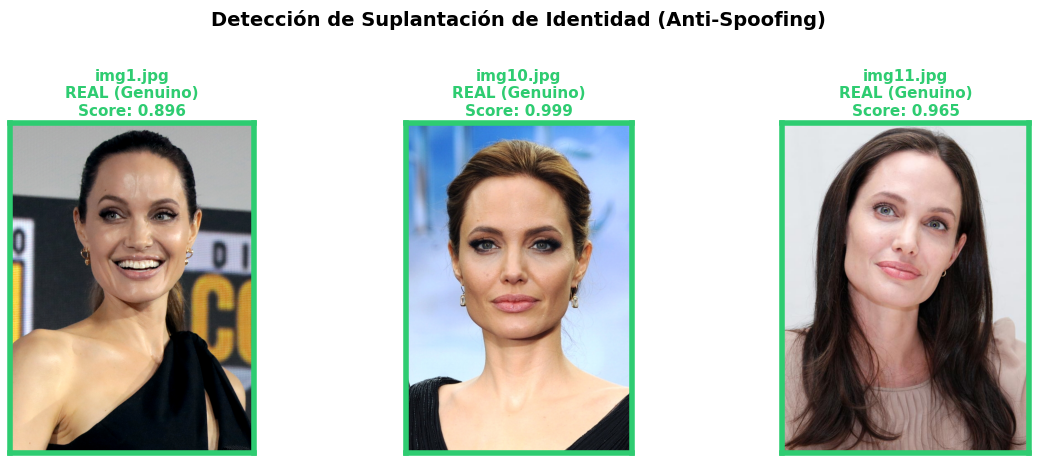

In [23]:
sample_paths = imgs[:3]
fig, axes = plt.subplots(1, len(sample_paths), figsize=(4 * len(sample_paths), 4.5))
axes = np.atleast_1d(axes)

print("=== ANALIZANDO INTEGRIDAD FACIAL (ANTI-SPOOFING) ===\n")

for idx, p in enumerate(sample_paths):
    try:
        # Extraemos la cara activando el análisis de anti-spoofing
        face_objs = DeepFace.extract_faces(p, anti_spoofing=True, enforce_detection=False)
        face_obj = face_objs[0]

        is_real = face_obj.get("is_real", True)
        score = face_obj.get("antispoof_score", 0.0)

        # Cargamos y preparamos la imagen
        img_rgb = load(p)

        # Definimos color y etiqueta según el veredicto
        color = "#2ecc71" if is_real else "#e74c3c" # Verde (Genuino) o Rojo (Falso)
        label = "REAL (Genuino)" if is_real else "SPOOF (Falso)"

        # Dibujamos en el gráfico
        axes[idx].imshow(img_rgb)
        axes[idx].set_title(f"{os.path.basename(p)}\n{label}\nScore: {score:.3f}",
                            color=color, fontsize=11, fontweight="bold")

        # Agregamos un borde decorativo de color para denotar el estatus de forma instantánea
        for spine in axes[idx].spines.values():
            spine.set_edgecolor(color)
            spine.set_linewidth(4)

    except Exception as e:
        axes[idx].imshow(load(p))
        axes[idx].set_title(f"{os.path.basename(p)}\nError al evaluar", color="gray", fontsize=10)
        axes[idx].axis("off")

    axes[idx].set_xticks([])
    axes[idx].set_yticks([])

plt.suptitle("Detección de Suplantación de Identidad (Anti-Spoofing)", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

## 8. Video: análisis fotograma a fotograma

In [24]:
# Descargamos un video de ejemplo con rostros reales para un análisis dinámico
import os
import urllib.request

VIDEO_IN = "input.mp4"
video_url = "https://github.com/intel-iot-devkit/sample-videos/raw/master/face-demographics-walking-and-standing.mp4"

print("=== PREPARANDO VIDEO DE EJEMPLO ===")
if not os.path.exists(VIDEO_IN):
    try:
        print("Descargando video de muestra (rostros en movimiento)...")
        urllib.request.urlretrieve(video_url, VIDEO_IN)
        print("¡Descarga completada con éxito!")
    except Exception as e:
        print("No se pudo descargar el video externo. Generando video alternativo...")
        import cv2
        h, w = 480, 480
        vw = cv2.VideoWriter(VIDEO_IN, cv2.VideoWriter_fourcc(*"mp4v"), 5, (w, h))
        for p in imgs[:20]:
            fr = cv2.resize(cv2.imread(p), (w, h))
            for _ in range(5):
                vw.write(fr)
        vw.release()
else:
    print("El video de ejemplo ya existe localmente.")

print("Video listo para procesar:", VIDEO_IN)

=== PREPARANDO VIDEO DE EJEMPLO ===
Descargando video de muestra (rostros en movimiento)...
No se pudo descargar el video externo. Generando video alternativo...
Video listo para procesar: input.mp4


In [27]:
cap = cv2.VideoCapture(VIDEO_IN)
fps = cap.get(cv2.CAP_PROP_FPS) or 10
W, H = int(cap.get(3)), int(cap.get(4))
out = cv2.VideoWriter("raw.mp4", cv2.VideoWriter_fourcc(*"mp4v"), fps, (W, H))
n, STEP = 0, 3   # analiza 1 de cada 3 fotogramas
last = []
while cap.isOpened():
    ok, fr = cap.read()
    if not ok: break
    if n % STEP == 0:
        try:
            last = DeepFace.analyze(fr,
                                    actions=["emotion", "age", "gender"],
                                    detector_backend="opencv",
                                    enforce_detection=False, silent=True)
        except Exception: last = []
    for r in last:
        a = r["region"]
        if a["w"] == 0: continue
        cv2.rectangle(fr, (a["x"], a["y"]),
         (a["x"]+a["w"], a["y"]+a["h"]), (0, 255, 0), 2)
        cv2.putText(fr, f"{r['dominant_emotion']} | {r['age']} | {r['dominant_gender']}",
                    (a["x"], max(a["y"]-8, 15)),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 255, 0), 2)
    out.write(fr); n += 1
cap.release(); out.release()
!ffmpeg -y -loglevel error -i raw.mp4 -vcodec libx264 output.mp4   # códec compatible con el navegador

from IPython.display import HTML
from base64 import b64encode
data = b64encode(open("output.mp4", "rb").read()).decode()
HTML(f'<video width=480 controls><source src="data:video/mp4;base64,{data}" type="video/mp4"></video>')